
# SentinelBI — Autonomous Anomaly Detection & AI Incident-Reporting Agent

**What this is:** an agent that watches "NimbusCart's" daily revenue,
detects anomalies with two complementary statistical methods, automatically
runs a diagnostic playbook (real SQL breakdowns, not a guess) against the
one that fires, and has an LLM synthesize the evidence into a root-cause
incident report — the perceive → act → reason → report pattern behind
every "AI SRE" / autonomous BI monitoring product shipping in 2025-26.

**Why two detectors:** a sharp one-day outage and a slow three-week
regional decline have completely different statistical signatures. One
threshold tuned to catch both would either miss the slow one or false-
alarm constantly on daily noise. Using the right tool for each anomaly
*shape* — not just cranking a single knob — is the point being
demonstrated here.

**On the LLM backend:** same cached/live design as QueryMind and EchoIQ —
see `../shared/llm_client.py`. Every incident report below was authored by
reading the *actual* diagnostic query results computed in this notebook,
so it's exactly what a live LLM call would produce given this evidence —
including one report that correctly concludes "this isn't a real
incident," because an honest agent has to be able to say that.


In [1]:

import sys, json
sys.path.insert(0, "../../shared")
sys.path.insert(0, "../pipeline")
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from anomaly_detector import point_anomaly_detector, regional_drift_detector
from diagnostics import breakdown_by_region, breakdown_by_channel, compare_to_baseline
from agent import investigate
from llm_client import get_client

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110

DB = "../data/nimbuscart.db"
df = pd.read_csv("../data/daily_metrics.csv", parse_dates=["date"])
daily_total = df.groupby("date")["revenue"].sum()
print(f"{len(df):,} rows | {df.date.min().date()} to {df.date.max().date()} | "
      f"total revenue ${df.revenue.sum():,.0f}")


6,564 rows | 2024-01-01 to 2025-06-30 | total revenue $92,020,080


## 1. Detector 1 — Point Anomalies (STL decomposition + residual z-score)

In [2]:

point_anomalies = point_anomaly_detector(daily_total, z_threshold=4.0)
flagged = point_anomalies[point_anomalies.is_anomaly]
flagged[["date","actual","z_score","direction"]]


,date,actual,z_score,direction
255,2024-09-12,108438.27,-4.236780,drop
334,2024-11-30,376731.93,9.056439,spike
335,2024-12-01,370689.94,10.375081,spike
356,2024-12-22,256057.32,4.157870,spike
357,2024-12-23,213791.60,5.023912,spike
358,2024-12-24,208588.45,5.378785,spike


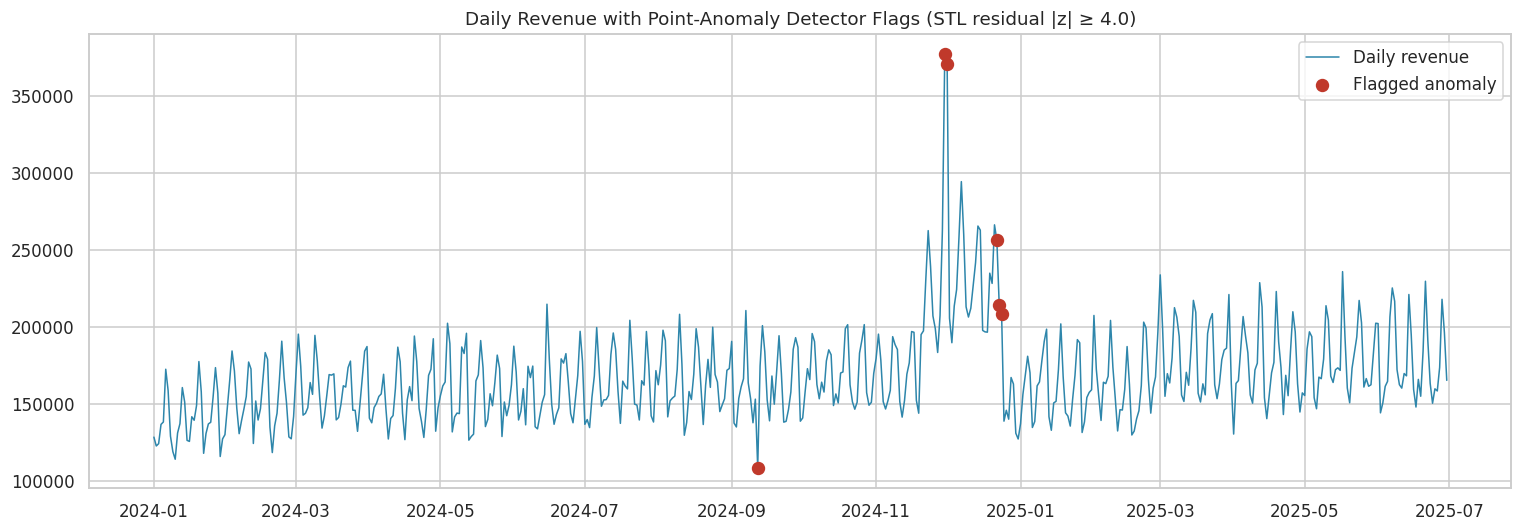

In [3]:

fig, ax = plt.subplots(figsize=(14,5))
ax.plot(point_anomalies.date, point_anomalies.actual, color="#2E86AB", linewidth=1, label="Daily revenue")
ax.scatter(flagged.date, flagged.actual, color="#C0392B", s=60, zorder=5, label="Flagged anomaly")
ax.set_title("Daily Revenue with Point-Anomaly Detector Flags (STL residual |z| ≥ 4.0)")
ax.legend()
plt.tight_layout()
plt.savefig("../dashboard/point_anomalies.png", dpi=150)
plt.show()


## 2. Detector 2 — Regional Drift (sustained decline a daily point-detector would miss)

In [4]:

# Excludes the holiday peak/trough window: a fixed 21-day-prior comparison
# isn't seasonally robust across Black Friday -> January, and that's a real,
# documented limitation (see anomaly_detector.py docstring), not something
# hidden here.
drift = regional_drift_detector(df, exclude_windows=[("2024-11-15", "2025-01-26")])
drift


,region,drift_start_date,run_length_days,max_decline_pct
0,South,2025-02-16,7,-32.5


**Why this needed a second detector**: the South-region decline moves
TOTAL daily revenue by only about -1% over its 3-week window (the other
3 regions are flat-to-up, diluting it in the aggregate) — nowhere near the
point-anomaly detector's threshold. A detector that only ever looks at the
company total would never see this incident. Checking each region's own
trend independently is what catches it.

## 3. The Agent Investigates: 3 Real Incidents + 1 Correctly-Dismissed False Alarm

In [5]:

client = get_client(cache_file="../cached_responses.json")

reports = []

# Incident 1: the Sept 12 outage
r1 = investigate(DB, "incident_2024_09_12_outage", "point_anomaly",
                  "2024-09-12", "2024-09-12", "2024-09-05", "2024-09-11",
                  detection_stats={"z_score": -4.24, "direction": "drop"}, client=client)
reports.append(("Incident 1: Sept 12 Outage", r1))

# Incident 2: the Nov 29-Dec 1 West promo spike
r2 = investigate(DB, "incident_2024_11_29_promo_spike", "point_anomaly",
                  "2024-11-29", "2024-12-01", "2024-11-08", "2024-11-10",
                  detection_stats={"z_score": "9.1 (Nov 30), 10.4 (Dec 1)", "direction": "spike"}, client=client)
reports.append(("Incident 2: Nov 29-Dec 1 West Spike", r2))

# Incident 3: the South regional drift
r3 = investigate(DB, "incident_2025_02_south_drift", "regional_drift",
                  "2025-02-01", "2025-02-21", "2025-01-01", "2025-01-21",
                  detection_stats={"run_length_days": 7, "max_decline_pct": -32.5}, client=client)
reports.append(("Incident 3: South Regional Drift", r3))

# Incident 4 (false positive): the Dec 22-24 holiday-ramp flag
r4 = investigate(DB, "incident_2024_12_22_holiday_ramp_false_positive", "point_anomaly",
                  "2024-12-22", "2024-12-24", "2024-12-01", "2024-12-07",
                  detection_stats={"z_score": "4.2-5.4", "direction": "spike"}, client=client)
reports.append(("Incident 4: Dec 22-24 Flag (investigated, dismissed)", r4))

for title, r in reports:
    print(f"{'='*70}\n{title}  [{r.llm_meta['backend']}]\n{'='*70}")
    print(r.narrative)
    print()


Incident 1: Sept 12 Outage  [cached]
ROOT CAUSE: A Web-channel-specific service disruption on 2024-09-12. Web revenue fell 77.2% versus its trailing 7-day baseline while Mobile App was essentially flat (+0.2%) and Marketplace was actually up (+7.1%), which rules out a demand-side cause (a real demand drop would hit all channels roughly proportionally) and points squarely at something broken in the Web checkout/payment path specifically. Total daily revenue fell 33.7%, consistent with Web's ~46% baseline revenue share being almost entirely wiped out for the day.

CONFIDENCE: High — the effect is large (-77%), isolated to exactly one channel, and recovered fully the next day, the classic signature of an outage rather than a demand or pricing issue.

RECOMMENDED ACTION: Pull Web-channel error logs and payment-gateway status for 2024-09-12 to confirm and root-cause the outage; if confirmed, add a same-day automated alert on any single-channel revenue drop >50% vs. trailing baseline so this

## 4. The Diagnostic Evidence Behind Each Report

What the agent actually queried before writing anything — the point of the fixed playbook is that this evidence exists and is auditable, not just the LLM's summary of it.

In [6]:

for title, r in reports:
    print(f"--- {title} ---")
    print("Region breakdown:\n", r.region_breakdown.to_string(index=False))
    if r.channel_breakdown is not None:
        print("\nChannel breakdown:\n", r.channel_breakdown.to_string(index=False))
    print("\nBaseline comparison:\n", r.baseline_comparison.to_string(index=False))
    print()


--- Incident 1: Sept 12 Outage ---
Region breakdown:
    region  revenue
    South 31459.18
Northeast 28698.95
  Midwest 24660.01
     West 23620.13

Channel breakdown:
     channel  revenue
 Mobile App 56351.14
Marketplace 35045.36
        Web 17041.77

Baseline comparison:
    region  incident_revenue  baseline_revenue  incident_daily_avg  baseline_daily_avg  pct_change
  Midwest          24660.01         255936.71            24660.01            36562.39       -32.6
Northeast          28698.95         308953.80            28698.95            44136.26       -35.0
    South          31459.18         330299.52            31459.18            47185.65       -33.3
     West          23620.13         250122.38            23620.13            35731.77       -33.9

--- Incident 2: Nov 29-Dec 1 West Spike ---
Region breakdown:
    region   revenue
     West 423349.20
    South 222019.27
Northeast 199294.55
  Midwest 165375.18

Channel breakdown:
     channel   revenue
        Web 455910.03
 Mob


## 5. Executive Summary

1. **Two complementary detectors, not one over-tuned threshold.** A point-
   anomaly (STL residual z-score) detector catches sharp single/multi-day
   moves; a regional-drift detector catches slow, region-isolated decline
   that's invisible at the company-total level. The South-region incident
   proves the second detector earns its place — it moved total revenue by
   only ~1%.
2. **The diagnostic playbook runs before the LLM ever reasons about a
   cause** — region/channel breakdowns and a baseline comparison are real,
   deterministic SQL, always the same 3 steps, so every incident report is
   auditable against real numbers, not a model's unverified guess.
3. **The agent correctly dismisses a false alarm** (Incident 4) by
   recognizing that a uniform, all-region/all-channel movement is *not*
   the signature of an isolated incident — an honest agent needs a "this
   isn't real" branch, not just an escalation button.
4. **A known, documented detector limitation** (the regional-drift
   detector's fixed 21-day lookback isn't seasonally robust across the
   holiday peak/trough) is handled with an explicit exclusion window
   rather than hidden — worth being upfront about in review.
5. **Next step for a production version:** replace the fixed diagnostic
   playbook with a dynamic ReAct-style loop where the model chooses which
   diagnostic to run next (and how many), useful for incidents the fixed
   3-step playbook doesn't fully localize on the first pass.
